## Imports

In [ ]:
#For local
from llmfromscratch.LLMArchitecture import LLM
import tiktoken
import numpy
from llmfromscratch.DatasetDataLoader import ClassificationFinetuneDataset
from llmfromscratch.Textgeneration import generate_text_simple, text_to_token_ids, token_ids_to_text
from llmfromscratch.LoRA import LoRALayer, LinearWithLoRA

# #for colab
# from LLMArchitecture import LLM
# import tiktoken
# import numpy
# from DatasetDataLoader import ClassificationFinetuneDataset
# from Textgeneration import generate_text_simple, text_to_token_ids, token_ids_to_text
# from LoRA import LoRALayer, LinearWithLoRA

import torch
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader
import random
import tiktoken
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

## Setup

In [ ]:
#Setting the seed
seed = 42
torch.manual_seed(seed)
np.random.seed(seed)
random.seed(seed)

#CONGIGURATION
CONFIG = {
    "vocab_size": 50257,   # Vocabulary size
    "context_length": 256, # Shortened context length (orig: 1024)
    "emb_dim": 384,        # Embedding dimension
    "n_heads": 6,         # Number of attention heads
    "n_layers": 6,        # Number of layers
    "drop_rate": 0.2,      # Dropout rate
    "qkv_bias": False,      # Query-key-value bias
    "Epoches": 10,
    "lr": 3e-4,
    "batch_size": 8,
    "eval_freq": 50
}

#Tokenizer
tokenizer = tiktoken.get_encoding("gpt2")

In [ ]:
#setting the device
device = 'cuda' if torch.cuda.is_available() else 'cpu'
device

'cuda'

## Loading & Pre-processing the data

In [ ]:
#For local
df = pd.read_csv(r"D:\Projects\LLMFromScratch\data\sentiment.csv")
df.head(5)

In [ ]:
# #For colab
# df = pd.read_csv("sentiment.csv")
# df.head(5)

,Text,Label,Sentiment,Conf_ModernBERT,Conf_DeBERTa
0,That thou hast wronged in the time o'erpast; F...,0,negative,0.9978,0.9997
1,"Most royal sir, from thence; from him, whose d...",1,positive,0.9588,0.9741
2,"One, Kate, that you must kiss, and be acquaint...",0,negative,0.9654,0.9145
3,Such a fellow is not to be talked withal. Away...,0,negative,0.9976,0.9987
4,"For though mine enemy thou hast ever been, Hig...",1,positive,0.9759,0.9696


In [ ]:
df = df[["Text", "Label"]]
label_names = {0: "negative", 1: "positive"}
print(df["Label"].value_counts())

Label
0    219
1    219
Name: count, dtype: int64


In [ ]:
df.head(5)

,Text,Label
0,That thou hast wronged in the time o'erpast; F...,0
1,"Most royal sir, from thence; from him, whose d...",1
2,"One, Kate, that you must kiss, and be acquaint...",0
3,Such a fellow is not to be talked withal. Away...,0
4,"For though mine enemy thou hast ever been, Hig...",1


In [ ]:
print("Dimensions of the data: ",df.shape)

Dimensions of the data:  (438, 2)


In [ ]:
#Split the dataset to train, test, val sets
train_df, temp_df = train_test_split(
    df, test_size=0.3, random_state=123, stratify=df["Label"]
)

val_df, test_df = train_test_split(
    temp_df, test_size=2/3, random_state=123, stratify=temp_df["Label"]
)

print(len(train_df), len(val_df), len(test_df))

#For Local
train_df.to_csv(r"D:\Projects\LLMFromScratch\data\classification_finetune_train.csv", index=False)
val_df.to_csv(r"D:\Projects\LLMFromScratch\data\classification_finetune_val.csv", index=False)
test_df.to_csv(r"D:\Projects\LLMFromScratch\data\classification_finetune_test.csv", index=False)

#For colab
# train_df.to_csv("classification_finetune_train.csv", index=False)
# val_df.to_csv("classification_finetune_val.csv", index=False)
# test_df.to_csv("classification_finetune_test.csv", index=False)

306 44 88


In [ ]:
# #DataSet
tokenizer = tiktoken.get_encoding("gpt2")

#For local
train_dataset = ClassificationFinetuneDataset(
    r"D:\Projects\LLMFromScratch\data\classification_finetune_train.csv",
    tokenizer, max_length=128
)
val_dataset = ClassificationFinetuneDataset(
    r"D:\Projects\LLMFromScratch\data\classification_finetune_val.csv",
    tokenizer, max_length=train_dataset.max_length
)
test_dataset = ClassificationFinetuneDataset(
    r"D:\Projects\LLMFromScratch\data\classification_finetune_test.csv",
    tokenizer, max_length=train_dataset.max_length
)

#For colab
# train_dataset = ClassificationFinetuneDataset(
#     "classification_finetune_train.csv",
#     tokenizer, max_length=128)

# val_dataset = ClassificationFinetuneDataset(
#     "classification_finetune_val.csv",
#     tokenizer, max_length=train_dataset.max_length)

# test_dataset = ClassificationFinetuneDataset("classification_finetune_test.csv",
#     tokenizer, max_length=train_dataset.max_length)

In [ ]:
#DataLoader
num_workers = 0
batch_size = 8

torch.manual_seed(123)

train_loader = DataLoader(
    dataset=train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=num_workers,
    drop_last=True,
)

val_loader = DataLoader(
    dataset=val_dataset,
    batch_size=batch_size,
    num_workers=num_workers,
    drop_last=False,
)

test_loader = DataLoader(
    dataset=test_dataset,
    batch_size=batch_size,
    num_workers=num_workers,
    drop_last=False,
)

In [ ]:
for input_batch, target_batch in train_loader:
    pass
print("Input batch dimensions:", input_batch.shape)
print("Label batch dimensions:", target_batch.shape)
print(f"{len(train_loader)} training batches")
print(f"{len(val_loader)} validation batches")
print(f"{len(test_loader)} test batches")

Input batch dimensions: torch.Size([8, 128])
Label batch dimensions: torch.Size([8])
38 training batches
6 validation batches
11 test batches


## Model setup

In [ ]:
def replace_linear_with_lora(model, rank, alpha):
    for name, module in model.named_children():
        if isinstance(module, torch.nn.MultiheadAttention):
            # Leave PyTorch's built-in attention alone (it reads out_proj.weight directly)
            continue
        if isinstance(module, torch.nn.Linear):
            setattr(model, name, LinearWithLoRA(module, rank, alpha))
        else:
            replace_linear_with_lora(module, rank, alpha)

In [ ]:
#CONGIGURATION (must match the training config)
CONFIG = {
        "vocab_size": 50257,   # Vocabulary size
        "context_length": 256, # Shortened context length (orig: 1024)
        "emb_dim": 384,        # Embedding dimension
        "n_heads": 6,          # Number of attention heads
        "n_layers": 6,         # Number of layers
        "drop_rate": 0.2,      # Dropout rate
        "qkv_bias": False      # Query-key-value bias
    }

#setting the device
device = 'cuda' if torch.cuda.is_available() else 'cpu'

#Tokenizer
tokenizer = tiktoken.get_encoding("gpt2")

#Loading the model
model = LLM(CONFIG)
#ckpt = torch.load(r"D:\Projects\LLMFromScratch\models\final_pretrained_model.pth", map_location=device, weights_only=True) #for local
ckpt = torch.load("final_pretrained_model.pth", map_location=device, weights_only=True) #for colab
state_dict = ckpt["model_state_dict"] if "model_state_dict" in ckpt else ckpt
model.load_state_dict(state_dict)
model.to(device)
model.eval()


LLM(
  (tok_emb): Embedding(50257, 384)
  (pos_emb): Embedding(256, 384)
  (drop_emb): Dropout(p=0.2, inplace=False)
  (trf_blocks): Sequential(
    (0): TransformerBlock(
      (att): MultiHeadAttention(
        (in_proj): Identity()
        (multihead_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=384, out_features=384, bias=False)
        )
        (proj): Linear(in_features=384, out_features=384, bias=True)
      )
      (ff): FeedForward(
        (layers): Sequential(
          (0): Linear(in_features=384, out_features=1536, bias=True)
          (1): GELU(approximate='tanh')
          (2): Linear(in_features=1536, out_features=384, bias=True)
        )
      )
      (norm1): LayerNorm((384,), eps=1e-05, elementwise_affine=True, bias=True)
      (norm2): LayerNorm((384,), eps=1e-05, elementwise_affine=True, bias=True)
      (drop_shortcut): Dropout(p=0.2, inplace=False)
    )
    (1): TransformerBlock(
      (att): MultiHeadAttention(
 

In [ ]:
#Freezing weights
for param in model.parameters():
    param.requires_grad = False

#Classification head
num_classes = train_df["Label"].nunique()
model.out_head = torch.nn.Linear(CONFIG["emb_dim"], num_classes)

#Apply Lora
replace_linear_with_lora(model, rank=16, alpha=16)

model.to(device)   # move everything to the device

LLM(
  (tok_emb): Embedding(50257, 384)
  (pos_emb): Embedding(256, 384)
  (drop_emb): Dropout(p=0.2, inplace=False)
  (trf_blocks): Sequential(
    (0): TransformerBlock(
      (att): MultiHeadAttention(
        (in_proj): Identity()
        (multihead_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=384, out_features=384, bias=False)
        )
        (proj): LinearWithLoRA(
          (linear): Linear(in_features=384, out_features=384, bias=True)
          (lora): LoRALayer()
        )
      )
      (ff): FeedForward(
        (layers): Sequential(
          (0): LinearWithLoRA(
            (linear): Linear(in_features=384, out_features=1536, bias=True)
            (lora): LoRALayer()
          )
          (1): GELU(approximate='tanh')
          (2): LinearWithLoRA(
            (linear): Linear(in_features=1536, out_features=384, bias=True)
            (lora): LoRALayer()
          )
        )
      )
      (norm1): LayerNorm((384,), eps=1e-

## Utility Functions

In [ ]:
def last_token_logits(model, input_batch, pad_id=50256):
    logits = model(input_batch)
    lengths = (input_batch != pad_id).sum(dim=1)
    idx = (lengths - 1).clamp(min=0)
    return logits[torch.arange(logits.size(0), device=logits.device), idx, :]

In [ ]:
@torch.no_grad()  # Disable gradient tracking for efficiency
def calc_accuracy_loader(data_loader, model, device, num_batches=None):
    model.eval()
    correct_predictions, num_examples = 0, 0

    if num_batches is None:
        num_batches = len(data_loader)
    else:
        num_batches = min(num_batches, len(data_loader))
    for i, (input_batch, target_batch) in enumerate(data_loader):
        if i < num_batches:
            input_batch, target_batch = input_batch.to(device), target_batch.to(device)
            logits = last_token_logits(model, input_batch) # Logits of last output token
            predicted_labels = torch.argmax(logits, dim=-1)

            num_examples += predicted_labels.shape[0]
            correct_predictions += (predicted_labels == target_batch).sum().item()
        else:
            break
    return correct_predictions / max(num_examples, 1)


In [ ]:

def calc_loss_batch(input_batch, target_batch, model, device):
    input_batch, target_batch = input_batch.to(device), target_batch.to(device)
    logits = last_token_logits(model, input_batch)
    loss = torch.nn.functional.cross_entropy(logits, target_batch)
    return loss

In [ ]:
def calc_loss_loader(data_loader, model, device, num_batches=None):
    total_loss = 0.
    if len(data_loader) == 0:
        return float("nan")
    elif num_batches is None:
        num_batches = len(data_loader)
    else:
        # Reduce the number of batches to match the total number of batches in the data loader
        # if num_batches exceeds the number of batches in the data loader
        num_batches = min(num_batches, len(data_loader))
    for i, (input_batch, target_batch) in enumerate(data_loader):
        if i < num_batches:
            loss = calc_loss_batch(input_batch, target_batch, model, device)
            total_loss += loss.item()
        else:
            break
    return total_loss / num_batches



In [ ]:
def evaluate_model(model, train_loader, val_loader, device, eval_iter):
    model.eval()
    with torch.no_grad():
        train_loss = calc_loss_loader(train_loader, model, device, num_batches=eval_iter)
        val_loss = calc_loss_loader(val_loader, model, device, num_batches=eval_iter)
    model.train()
    return train_loss, val_loss


## Training

In [ ]:
def train_classifier(model, train_loader, val_loader, optimizer, device, num_epochs,
                            eval_freq, eval_iter):
    # Initialize lists to track losses and tokens seen
    train_losses, val_losses, train_accs, val_accs = [], [], [], []
    examples_seen, global_step = 0, -1

    # Main training loop
    for epoch in range(num_epochs):
        model.train()  # Set model to training mode

        for input_batch, target_batch in train_loader:
            optimizer.zero_grad()  # Reset loss gradients from previous batch iteration
            loss = calc_loss_batch(input_batch, target_batch, model, device)
            loss.backward()  # Calculate loss gradients
            optimizer.step()  # Update model weights using loss gradients
            examples_seen += input_batch.shape[0]  # New: track examples instead of tokens
            global_step += 1

            # Optional evaluation step
            if global_step % eval_freq == 0:
                train_loss, val_loss = evaluate_model(
                    model, train_loader, val_loader, device, eval_iter)
                train_losses.append(train_loss)
                val_losses.append(val_loss)
                print(f"Ep {epoch+1} (Step {global_step:06d}): "
                      f"Train loss {train_loss:.3f}, Val loss {val_loss:.3f}")

        # Calculate accuracy after each epoch
        train_accuracy = calc_accuracy_loader(train_loader, model, device, num_batches=eval_iter)
        val_accuracy = calc_accuracy_loader(val_loader, model, device, num_batches=eval_iter)
        print(f"Training accuracy: {train_accuracy*100:.2f}% | ", end="")
        print(f"Validation accuracy: {val_accuracy*100:.2f}%")
        train_accs.append(train_accuracy)
        val_accs.append(val_accuracy)

    return train_losses, val_losses, train_accs, val_accs, examples_seen


def plot_values(epochs_seen, examples_seen, train_values, val_values, label="loss"):
    fig, ax1 = plt.subplots(figsize=(5, 3))

    # Plot training and validation loss against epochs
    ax1.plot(epochs_seen, train_values, label=f"Training {label}")
    ax1.plot(epochs_seen, val_values, linestyle="-.", label=f"Validation {label}")
    ax1.set_xlabel("Epochs")
    ax1.set_ylabel(label.capitalize())
    ax1.legend()

    # Create a second x-axis for tokens seen
    ax2 = ax1.twiny()  # Create a second x-axis that shares the same y-axis
    ax2.plot(examples_seen, train_values, alpha=0)  # Invisible plot for aligning ticks
    ax2.set_xlabel("Examples seen")

    fig.tight_layout()  # Adjust layout to make room
    plt.savefig(f"{label}-plot.pdf")
    plt.show()

In [ ]:
print(device)

cuda


In [ ]:
optimizer = torch.optim.AdamW(model.parameters(), lr=8e-4, weight_decay=0.1)

num_epochs = 8
train_losses, val_losses, train_accs, val_accs, examples_seen = train_classifier(
    model, train_loader, val_loader, optimizer, device,
    num_epochs=num_epochs, eval_freq=50, eval_iter=5,
)

Ep 1 (Step 000000): Train loss 0.735, Val loss 0.735
Training accuracy: 50.00% | Validation accuracy: 62.50%
Ep 2 (Step 000050): Train loss 0.520, Val loss 0.682
Training accuracy: 80.00% | Validation accuracy: 70.00%
Ep 3 (Step 000100): Train loss 0.518, Val loss 0.618
Training accuracy: 90.00% | Validation accuracy: 65.00%
Ep 4 (Step 000150): Train loss 0.331, Val loss 0.788
Training accuracy: 87.50% | Validation accuracy: 57.50%
Training accuracy: 95.00% | Validation accuracy: 62.50%
Ep 6 (Step 000200): Train loss 0.092, Val loss 0.721
Training accuracy: 97.50% | Validation accuracy: 77.50%
Ep 7 (Step 000250): Train loss 0.054, Val loss 1.058
Training accuracy: 97.50% | Validation accuracy: 75.00%
Ep 8 (Step 000300): Train loss 0.009, Val loss 1.018
Training accuracy: 100.00% | Validation accuracy: 70.00%


In [ ]:
print("Train acc:", calc_accuracy_loader(train_loader, model, device))
print("Val acc:  ", calc_accuracy_loader(val_loader, model, device))
print("Test acc: ", calc_accuracy_loader(test_loader, model, device))

Train acc: 0.9967105263157895
Val acc:   0.6590909090909091
Test acc:  0.6136363636363636


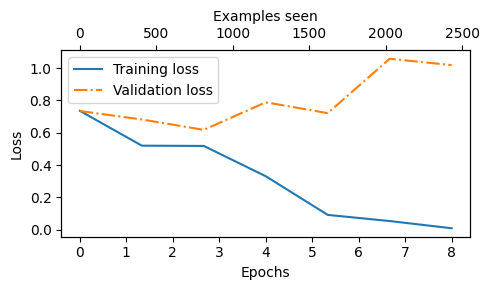

In [ ]:
epochs_tensor = torch.linspace(0, num_epochs, len(train_losses))
examples_seen_tensor = torch.linspace(0, examples_seen, len(train_losses))

plot_values(epochs_tensor, examples_seen_tensor, train_losses, val_losses, label="loss")

In [ ]:
# #Saving the trained model for colab
# print("Saving the model.............")
# torch.save({
#     "model_state_dict": model.state_dict(),
#     "optimizer_state_dict": optimizer.state_dict(),
# }, r"classification_finetuned_model.pth")
# print("Model saved...............")


# #Saving the trained model for local
print("Saving the model.............")
torch.save({
    "model_state_dict": model.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),
}, r"D:\Projects\LLMFromScratch\models\final_pretrained_model.pth")
print("Model saved...............")

Saving the model.............
Model saved...............
